In [10]:

import sqlite3
from pathlib import Path

DB_PATH = Path(r"C:\Users\G614JV\Desktop\Olist\olist_kpi.db")

if not DB_PATH.exists():
    raise FileNotFoundError(f"Database not found: {DB_PATH}")

conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON")

print("Connected to:", DB_PATH)


Connected to: C:\Users\G614JV\Desktop\Olist\olist_kpi.db


In [11]:

required_tables = [
    "stg_customers",
    "stg_sellers",
    "stg_category_translation",
    "stg_products",
    "stg_orders",
    "stg_order_items",
    "stg_order_reviews",
    "customers",
    "sellers",
    "category_translation",
    "products",
    "orders",
    "order_items",
    "order_reviews",
]

existing_tables = {
    row[0]
    for row in conn.execute("""
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
    """).fetchall()
}

missing_tables = [
    table for table in required_tables
    if table not in existing_tables
]

if missing_tables:
    print("Missing tables:", missing_tables)
else:
    print("All required tables exist.")


All required tables exist.


In [12]:

tables_to_check = [
    "stg_customers",
    "stg_sellers",
    "stg_category_translation",
    "stg_products",
    "stg_orders",
    "stg_order_items",
    "stg_order_reviews",
    "customers",
    "sellers",
    "category_translation",
    "products",
    "orders",
    "order_items",
    "order_reviews",
]

for table in tables_to_check:
    count = conn.execute(
        f'SELECT COUNT(*) FROM "{table}"'
    ).fetchone()[0]
    print(f"{table}: {count:,} rows")


stg_customers: 99,441 rows
stg_sellers: 3,095 rows
stg_category_translation: 71 rows
stg_products: 32,951 rows
stg_orders: 99,441 rows
stg_order_items: 112,650 rows
stg_order_reviews: 99,224 rows
customers: 0 rows
sellers: 0 rows
category_translation: 0 rows
products: 0 rows
orders: 0 rows
order_items: 0 rows
order_reviews: 0 rows


In [14]:

from pathlib import Path

DB_PATH = Path(r"C:\Users\G614JV\Desktop\Olist\olist_kpi.db")
SQL_PATH = Path(r"C:\Users\G614JV\Desktop\Olist\queries.sql")

# Connect to the correct database if needed
if "conn" not in globals():
    conn = sqlite3.connect(DB_PATH)

conn.execute("PRAGMA foreign_keys = ON")

# Read your SQL file
if not SQL_PATH.exists():
    raise FileNotFoundError(f"SQL file not found: {SQL_PATH}")

sql_script = SQL_PATH.read_text(encoding="utf-8")

# Execute the SQL script
try:
    conn.executescript(sql_script)
    print("queries.sql executed successfully.")
except Exception as e:
    if conn.in_transaction:
        conn.rollback()
    print("SQL execution failed:", e)
    raise


queries.sql executed successfully.


In [15]:

tables = [
    "customers",
    "sellers",
    "category_translation",
    "products",
    "orders",
    "order_items",
    "order_reviews",
]

print("FINAL TABLE COUNTS")
print("-" * 40)

for table in tables:
    count = conn.execute(
        f'SELECT COUNT(*) FROM "{table}"'
    ).fetchone()[0]
    print(f"{table}: {count:,}")

violations = conn.execute(
    "PRAGMA foreign_key_check"
).fetchall()

print("\nForeign-key violations:", violations)

if not violations:
    print("PASS: All foreign-key relationships are valid.")


FINAL TABLE COUNTS
----------------------------------------
customers: 99,441
sellers: 3,095
category_translation: 73
products: 32,951
orders: 99,441
order_items: 112,650
order_reviews: 99,224

Foreign-key violations: []
PASS: All foreign-key relationships are valid.


In [16]:

import sqlite3
import pandas as pd
from pathlib import Path
from IPython.display import display

# File locations
folder = Path(r"C:\Users\G614JV\Desktop\Olist")
db_path = folder / "olist_kpi.db"
sql_path = folder / "kpi_analysis.sql"
output_folder = folder / "kpi_outputs"

# Check files
if not db_path.exists():
    raise FileNotFoundError(f"Database not found: {db_path}")

if not sql_path.exists():
    raise FileNotFoundError(f"SQL file not found: {sql_path}")

# Connect to the database
conn = sqlite3.connect(db_path)

# Create a folder for the results
output_folder.mkdir(exist_ok=True)

# Read and separate the SQL queries
sql_text = sql_path.read_text(encoding="utf-8")
statements = [
    statement.strip()
    for statement in sql_text.split(";")
    if statement.strip()
]

results = {}

for number, statement in enumerate(statements, start=1):
    try:
        # Run each query and store its result
        df = pd.read_sql_query(statement, conn)

        if df.empty and len(df.columns) == 0:
            continue

        query_name = f"Q{number:02d}"
        results[query_name] = df

        # Save the result to CSV
        output_path = output_folder / f"{query_name}.csv"
        df.to_csv(output_path, index=False)

        print(f"\n{query_name} — {len(df):,} rows")
        display(df.head(15))

    except Exception as e:
        print(f"\nQuery {number} failed: {e}")

print("\nAnalysis finished.")
print("Results folder:", output_folder.resolve())
print("Successful query results:", len(results))



Analysis finished.
Results folder: C:\Users\G614JV\Desktop\Olist\kpi_outputs
Successful query results: 0


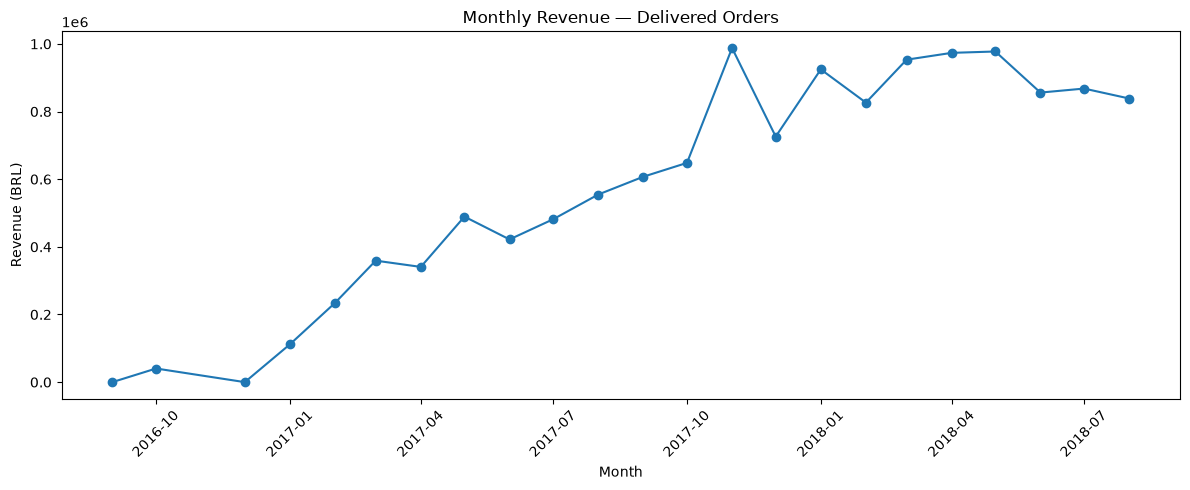

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

monthly["order_month"] = pd.to_datetime(monthly["order_month"])

plt.figure(figsize=(12, 5))
plt.plot(
    monthly["order_month"],
    monthly["monthly_revenue"],
    marker="o"
)

plt.title("Monthly Revenue — Delivered Orders")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
print(monthly.columns.tolist())
display(monthly.head())

['order_month', 'monthly_revenue']


,order_month,monthly_revenue
0,2016-09-01,134.97
1,2016-10-01,40325.11
2,2016-12-01,10.90
3,2017-01-01,111798.36
4,2017-02-01,234223.40


In [23]:
import pandas as pd

conn.executescript("""
DROP VIEW IF EXISTS vw_delivered_order_items;

CREATE VIEW vw_delivered_order_items AS
WITH review_by_order AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score,
        COUNT(*) AS review_count
    FROM order_reviews
    GROUP BY order_id
)
SELECT
    o.order_id,
    o.customer_id,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    oi.order_item_id,
    oi.product_id,
    oi.seller_id,
    oi.price,
    oi.freight_value,
    p.product_category_name,
    COALESCE(
        c.product_category_name_english,
        p.product_category_name,
        'unknown'
    ) AS category_name,
    r.review_score,
    COALESCE(r.review_count, 0) AS review_count,

    CASE
        WHEN o.order_delivered_customer_date IS NOT NULL
        THEN julianday(o.order_delivered_customer_date)
           - julianday(o.order_purchase_timestamp)
    END AS delivery_days,

    CASE
        WHEN o.order_delivered_customer_date IS NOT NULL
         AND o.order_estimated_delivery_date IS NOT NULL
        THEN julianday(o.order_delivered_customer_date)
           - julianday(o.order_estimated_delivery_date)
    END AS delivery_delay_days

FROM orders AS o
JOIN order_items AS oi
    ON o.order_id = oi.order_id
LEFT JOIN products AS p
    ON oi.product_id = p.product_id
LEFT JOIN category_translation AS c
    ON p.product_category_name = c.product_category_name
LEFT JOIN review_by_order AS r
    ON o.order_id = r.order_id
WHERE o.order_status = 'delivered';
""")

print("Analytical view created successfully.")

Analytical view created successfully.


In [24]:
reconciliation = pd.read_sql_query("""
WITH source_revenue AS (
    SELECT
        COUNT(*) AS item_rows,
        SUM(oi.price) AS revenue
    FROM orders AS o
    JOIN order_items AS oi
        ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
),
view_revenue AS (
    SELECT
        COUNT(*) AS item_rows,
        SUM(price) AS revenue
    FROM vw_delivered_order_items
)
SELECT
    s.item_rows AS source_item_rows,
    v.item_rows AS view_item_rows,
    ROUND(s.revenue, 2) AS source_revenue_brl,
    ROUND(v.revenue, 2) AS view_revenue_brl,
    ROUND(s.revenue - v.revenue, 2) AS revenue_difference_brl
FROM source_revenue AS s
CROSS JOIN view_revenue AS v;
""", conn)

display(reconciliation)

,source_item_rows,view_item_rows,source_revenue_brl,view_revenue_brl,revenue_difference_brl
0,110197,110197,13221498.11,13221498.11,0.0


In [25]:
from pathlib import Path

output_dir = Path(r"C:\Users\G614JV\Desktop\Olist\kpi_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

monthly = pd.read_sql_query("""
SELECT
    strftime('%Y-%m', order_purchase_timestamp) AS order_month,
    ROUND(SUM(price), 2) AS monthly_revenue
FROM vw_delivered_order_items
GROUP BY strftime('%Y-%m', order_purchase_timestamp)
ORDER BY order_month;
""", conn)

monthly.to_csv(output_dir / "Q03.csv", index=False)

print("Saved:", output_dir / "Q03.csv")
display(monthly.head())

Saved: C:\Users\G614JV\Desktop\Olist\kpi_outputs\Q03.csv


,order_month,monthly_revenue
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40


In [26]:
overall_kpis = pd.read_sql_query("""
WITH delivered_orders AS (
    SELECT
        order_id,
        order_purchase_timestamp,
        order_delivered_customer_date,
        order_estimated_delivery_date,
        julianday(order_delivered_customer_date)
            - julianday(order_purchase_timestamp) AS delivery_days,
        julianday(order_delivered_customer_date)
            - julianday(order_estimated_delivery_date) AS delivery_delay_days
    FROM orders
    WHERE order_status = 'delivered'
),
order_revenue AS (
    SELECT
        o.order_id,
        SUM(oi.price) AS revenue
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY o.order_id
),
review_by_order AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score
    FROM order_reviews
    GROUP BY order_id
)
SELECT
    COUNT(*) AS delivered_orders,
    (SELECT COUNT(*) FROM order_items oi
     JOIN delivered_orders d ON d.order_id = oi.order_id)
        AS delivered_item_rows,
    ROUND((SELECT SUM(revenue) FROM order_revenue), 2)
        AS total_revenue_brl,
    ROUND((SELECT AVG(revenue) FROM order_revenue), 2)
        AS average_order_value_brl,
    ROUND(AVG(d.delivery_days), 2) AS avg_delivery_days,
    ROUND(AVG(d.delivery_delay_days), 2) AS avg_delivery_delay_days,
    ROUND((
        SELECT AVG(r.review_score)
        FROM delivered_orders d2
        JOIN review_by_order r ON r.order_id = d2.order_id
    ), 2) AS avg_review_score
FROM delivered_orders d
WHERE d.order_delivered_customer_date IS NOT NULL;
""", conn)

display(overall_kpis)

,delivered_orders,delivered_item_rows,total_revenue_brl,average_order_value_brl,avg_delivery_days,avg_delivery_delay_days,avg_review_score
0,96470,110197,13221498.11,137.04,12.56,-11.18,4.16


In [27]:
monthly_kpis = pd.read_sql_query("""
WITH monthly_orders AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS order_month,
        order_id
    FROM orders
    WHERE order_status = 'delivered'
),
order_revenue AS (
    SELECT
        mo.order_month,
        mo.order_id,
        SUM(oi.price) AS revenue
    FROM monthly_orders mo
    JOIN order_items oi ON mo.order_id = oi.order_id
    GROUP BY mo.order_month, mo.order_id
)
SELECT
    order_month,
    COUNT(*) AS delivered_orders,
    ROUND(SUM(revenue), 2) AS monthly_revenue,
    ROUND(AVG(revenue), 2) AS average_order_value
FROM order_revenue
GROUP BY order_month
ORDER BY order_month;
""", conn)

display(monthly_kpis.head(10))

monthly_kpis.to_csv(
    output_dir / "Q04_monthly_kpis.csv",
    index=False
)

,order_month,delivered_orders,monthly_revenue,average_order_value
0,2016-09,1,134.97,134.97
1,2016-10,265,40325.11,152.17
2,2016-12,1,10.90,10.90
3,2017-01,750,111798.36,149.06
4,2017-02,1653,234223.40,141.70
5,2017-03,2546,359198.85,141.08
6,2017-04,2303,340669.68,147.92
7,2017-05,3546,489338.25,138.00
8,2017-06,3135,421923.37,134.58
9,2017-07,3872,481604.52,124.38


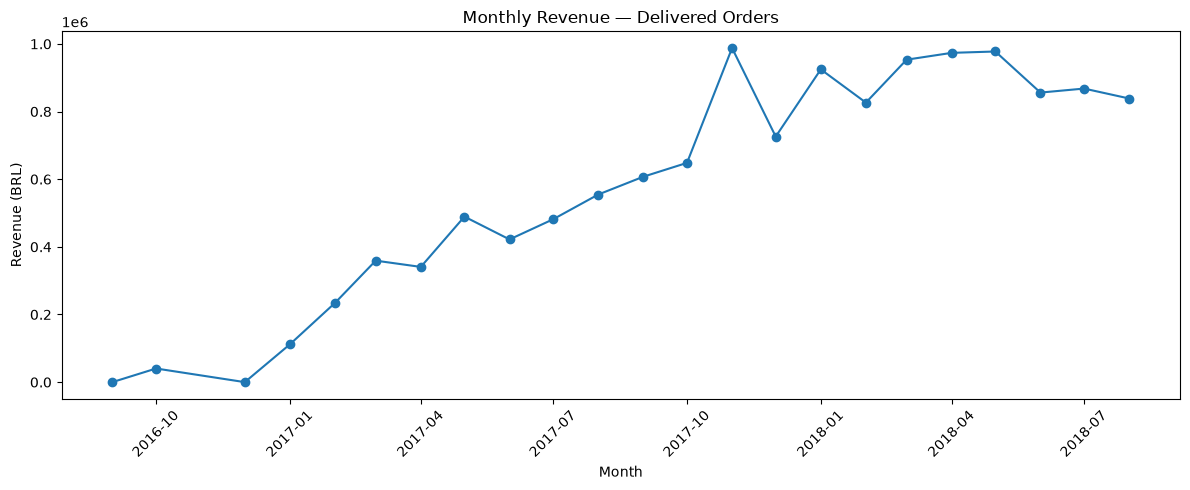

In [28]:
import matplotlib.pyplot as plt

monthly_kpis["order_month"] = pd.to_datetime(
    monthly_kpis["order_month"]
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_kpis["order_month"],
    monthly_kpis["monthly_revenue"],
    marker="o"
)
plt.title("Monthly Revenue — Delivered Orders")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
category_kpis = pd.read_sql_query("""
WITH category_reviews AS (
    SELECT
        oi.product_id,
        AVG(r.review_score) AS avg_review_score
    FROM order_items oi
    JOIN orders o ON o.order_id = oi.order_id
    LEFT JOIN order_reviews r ON r.order_id = o.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY oi.product_id
)
SELECT
    COALESCE(
        c.product_category_name_english,
        p.product_category_name,
        'unknown'
    ) AS category_name,
    ROUND(SUM(oi.price), 2) AS revenue_brl,
    COUNT(*) AS units_sold,
    COUNT(DISTINCT o.order_id) AS order_count,
    ROUND(AVG(cr.avg_review_score), 2) AS avg_review_score
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
LEFT JOIN products p ON oi.product_id = p.product_id
LEFT JOIN category_translation c
    ON p.product_category_name = c.product_category_name
LEFT JOIN category_reviews cr ON cr.product_id = oi.product_id
WHERE o.order_status = 'delivered'
GROUP BY category_name
ORDER BY revenue_brl DESC;
""", conn)

display(category_kpis.head(10))

category_kpis.to_csv(
    output_dir / "Q05_category_kpis.csv",
    index=False
)

,category_name,revenue_brl,units_sold,order_count,avg_review_score
0,health_beauty,1233131.72,9465,8647,4.19
1,watches_gifts,1166176.98,5859,5495,4.07
2,bed_bath_table,1023434.76,10953,9272,3.92
3,sports_leisure,954852.55,8431,7530,4.17
4,computers_accessories,888724.61,7644,6530,3.99
5,furniture_decor,711927.69,8160,6307,3.95
6,housewares,615628.69,6795,5743,4.11
7,cool_stuff,610204.10,3718,3559,4.20
8,auto,578966.65,4140,3810,4.11
9,toys,471286.48,4030,3804,4.21


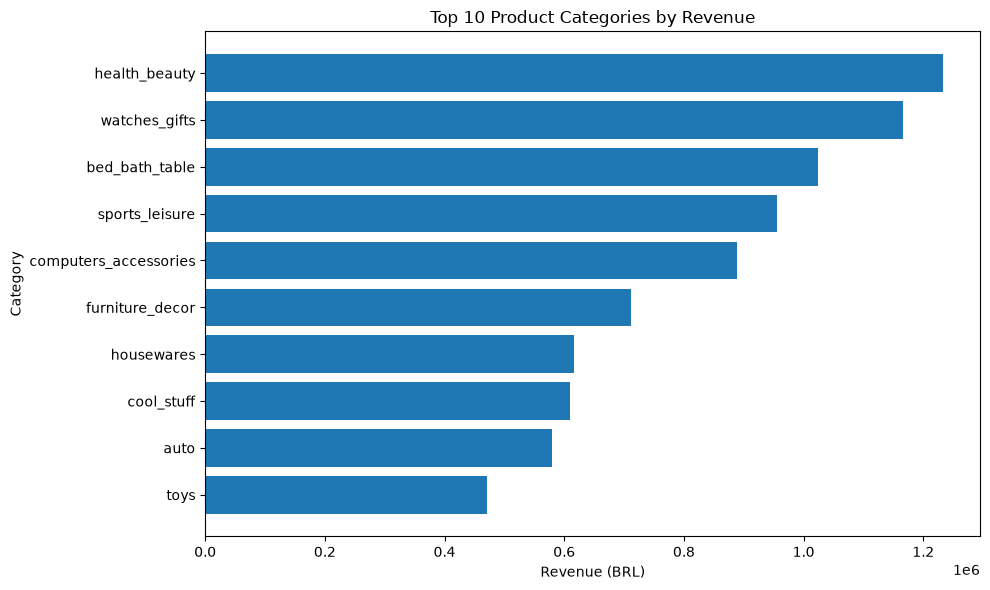

In [30]:
top_categories = category_kpis.nlargest(10, "revenue_brl").sort_values(
    "revenue_brl"
)

plt.figure(figsize=(10, 6))
plt.barh(top_categories["category_name"], top_categories["revenue_brl"])
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [31]:
category_revenue_ranking = pd.read_sql_query("""
SELECT
    COALESCE(
        c.product_category_name_english,
        p.product_category_name,
        'unknown'
    ) AS category_name,
    ROUND(SUM(oi.price), 2) AS revenue_brl,
    COUNT(DISTINCT o.order_id) AS order_count
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
LEFT JOIN products p ON oi.product_id = p.product_id
LEFT JOIN category_translation c
    ON p.product_category_name = c.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY category_name
HAVING COUNT(DISTINCT o.order_id) >= 100
ORDER BY revenue_brl DESC;
""", conn)

print("TOP 5 CATEGORIES BY REVENUE")
display(category_revenue_ranking.head(5))

print("BOTTOM 5 CATEGORIES BY REVENUE")
display(category_revenue_ranking.tail(5))

category_revenue_ranking.to_csv(
    output_dir / "Q07_category_revenue_ranking.csv",
    index=False
)

TOP 5 CATEGORIES BY REVENUE


,category_name,revenue_brl,order_count
0,health_beauty,1233131.72,8647
1,watches_gifts,1166176.98,5495
2,bed_bath_table,1023434.76,9272
3,sports_leisure,954852.55,7530
4,computers_accessories,888724.61,6530


BOTTOM 5 CATEGORIES BY REVENUE


,category_name,revenue_brl,order_count
47,books_technical,18702.23,256
48,food_drink,14942.88,221
49,fashion_male_clothing,10452.33,106
50,fashion_underwear_beach,9305.95,117
51,christmas_supplies,8737.84,125


In [32]:
category_review_ranking = pd.read_sql_query("""
WITH review_by_order AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score
    FROM order_reviews
    GROUP BY order_id
)
SELECT
    COALESCE(
        c.product_category_name_english,
        p.product_category_name,
        'unknown'
    ) AS category_name,
    ROUND(AVG(r.review_score), 2) AS avg_review_score,
    COUNT(DISTINCT o.order_id) AS reviewed_orders
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
LEFT JOIN products p ON oi.product_id = p.product_id
LEFT JOIN category_translation c
    ON p.product_category_name = c.product_category_name
JOIN review_by_order r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
GROUP BY category_name
HAVING COUNT(DISTINCT o.order_id) >= 100
ORDER BY avg_review_score DESC;
""", conn)

print("TOP 5 CATEGORIES BY REVIEW SCORE")
display(category_review_ranking.head(5))

print("BOTTOM 5 CATEGORIES BY REVIEW SCORE")
display(category_review_ranking.tail(5))

category_review_ranking.to_csv(
    output_dir / "Q08_category_review_ranking.csv",
    index=False
)

TOP 5 CATEGORIES BY REVIEW SCORE


,category_name,avg_review_score,reviewed_orders
0,books_general_interest,4.51,492
1,books_technical,4.39,255
2,food_drink,4.37,221
3,luggage_accessories,4.35,1015
4,fashion_shoes,4.29,231


BOTTOM 5 CATEGORIES BY REVIEW SCORE


,category_name,avg_review_score,reviewed_orders
47,home_confort,3.85,390
48,audio,3.84,345
49,fixed_telephony,3.76,209
50,fashion_male_clothing,3.76,105
51,office_furniture,3.51,1244


In [33]:
delivery_reviews = pd.read_sql_query("""
WITH review_by_order AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score
    FROM order_reviews
    GROUP BY order_id
)
SELECT
    o.order_id,
    julianday(o.order_delivered_customer_date)
      - julianday(o.order_estimated_delivery_date)
        AS delivery_delay_days,
    r.review_score
FROM orders o
JOIN review_by_order r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL;
""", conn)

delivery_reviews = delivery_reviews.dropna(
    subset=["delivery_delay_days", "review_score"]
)

correlation = delivery_reviews[
    ["delivery_delay_days", "review_score"]
].corr().iloc[0, 1]

print(f"Pearson correlation: {correlation:.3f}")
print(f"Orders included: {len(delivery_reviews):,}")

Pearson correlation: -0.267
Orders included: 95,824


In [34]:
overall_kpis.to_csv(
    output_dir / "Q04_overall_kpis.csv",
    index=False
)

print("Saved KPI outputs to:", output_dir)

Saved KPI outputs to: C:\Users\G614JV\Desktop\Olist\kpi_outputs


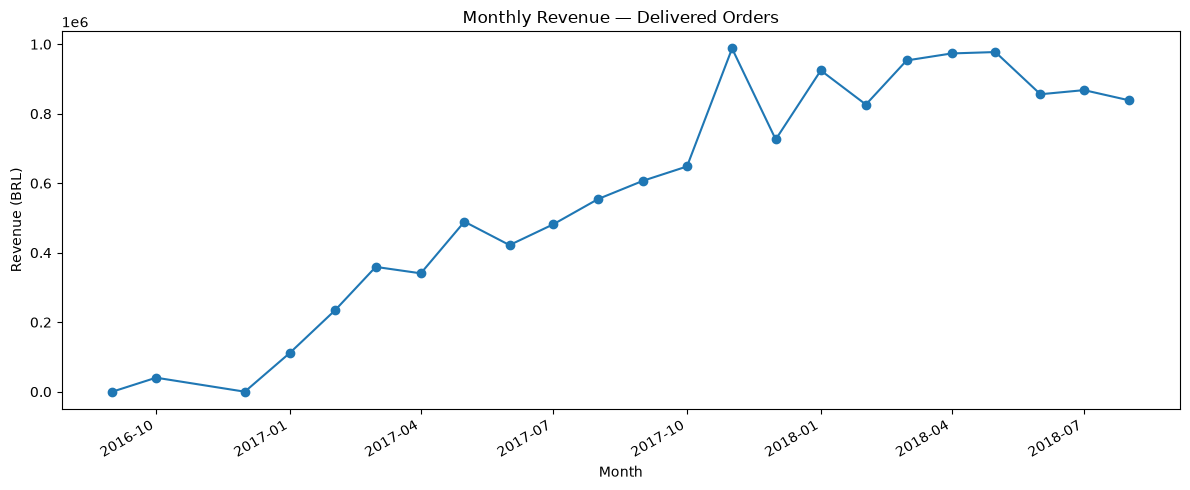

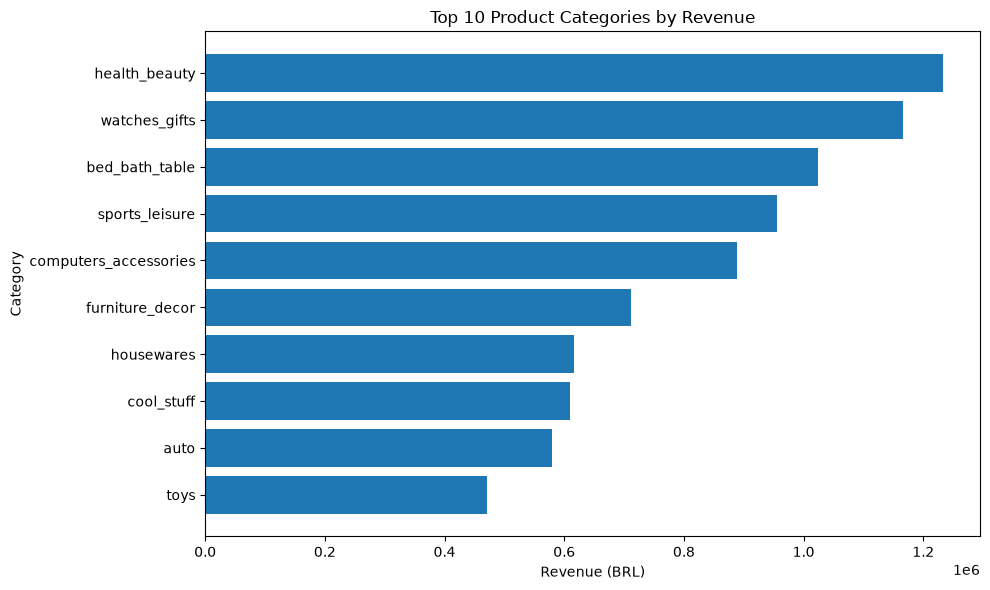

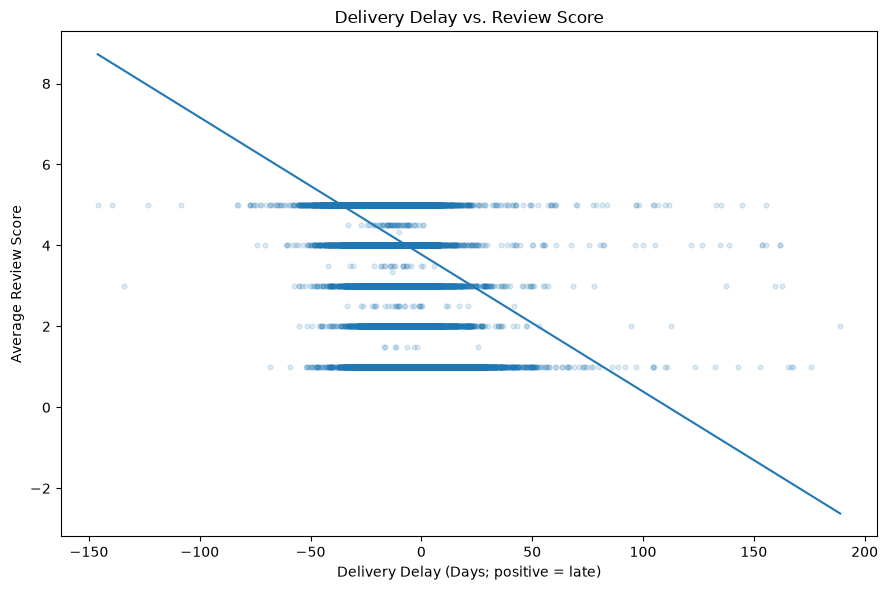

Saved charts:
C:\Users\G614JV\Desktop\Olist\kpi_outputs\chart_01_monthly_revenue.png
C:\Users\G614JV\Desktop\Olist\kpi_outputs\chart_02_top_categories.png
C:\Users\G614JV\Desktop\Olist\kpi_outputs\chart_03_delivery_vs_reviews.png


In [35]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

output_dir = Path(r"C:\Users\G614JV\Desktop\Olist\kpi_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Chart 1: Monthly revenue
monthly_plot = monthly_kpis.copy()
monthly_plot["order_month"] = pd.to_datetime(
    monthly_plot["order_month"]
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    monthly_plot["order_month"],
    monthly_plot["monthly_revenue"],
    marker="o"
)
ax.set_title("Monthly Revenue — Delivered Orders")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (BRL)")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(output_dir / "chart_01_monthly_revenue.png", dpi=150)
plt.show()
plt.close(fig)

# Chart 2: Top 10 categories by revenue
top10 = category_kpis.nlargest(10, "revenue_brl").sort_values(
    "revenue_brl"
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10["category_name"], top10["revenue_brl"])
ax.set_title("Top 10 Product Categories by Revenue")
ax.set_xlabel("Revenue (BRL)")
ax.set_ylabel("Category")
fig.tight_layout()
fig.savefig(output_dir / "chart_02_top_categories.png", dpi=150)
plt.show()
plt.close(fig)

# Chart 3: Delivery delay versus review score
plot_data = delivery_reviews.dropna(
    subset=["delivery_delay_days", "review_score"]
)

x = plot_data["delivery_delay_days"]
y = plot_data["review_score"]

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(x, y, alpha=0.15, s=12)

if len(plot_data) >= 2 and x.nunique() > 1:
    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(x_line, slope * x_line + intercept)

ax.set_title("Delivery Delay vs. Review Score")
ax.set_xlabel("Delivery Delay (Days; positive = late)")
ax.set_ylabel("Average Review Score")
fig.tight_layout()
fig.savefig(output_dir / "chart_03_delivery_vs_reviews.png", dpi=150)
plt.show()
plt.close(fig)

print("Saved charts:")
for filename in [
    "chart_01_monthly_revenue.png",
    "chart_02_top_categories.png",
    "chart_03_delivery_vs_reviews.png"
]:
    print(output_dir / filename)